In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, ttest_ind
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter

In [2]:
data_sumN = pd.read_table("NIPBL_data_3.txt")
data_sumN_fc = pd.read_table("NIPBL_data_FC_3.txt")
guides = ["0", "96", "206", "409", "848"]

In [3]:
palette=["#83aac3", "#3c627c", "#7f6b9e", "#3b304a"]

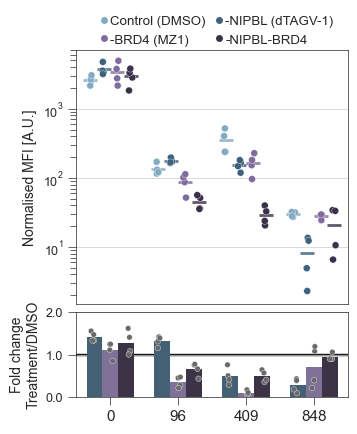

In [4]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
f, axs = plt.subplots(
    figsize=(3.5,4.5),
    nrows=2, 
    gridspec_kw={'height_ratios':[3,1], 'hspace':0.05}, 
    sharex=True,)

df=data_sumN

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG", "MZ1", "dTAG+MZ1"]

df=df[df["guide"].isin(order)]
df2=data_sumN_fc

g = sns.stripplot(data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette,
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5, ax=axs[0],
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette,
    hue_order=hue_order, order=order, dodge=.6, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=axs[0])


g.set(yscale="log", title="", ylim=[1.5, 7000])

axs[0].grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[0], markersize=6, label="Control (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[2], markersize=6, label="-BRD4 (MZ1)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[1], markersize=6, label="-NIPBL (dTAGV-1)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[3], markersize=6, label="-NIPBL-BRD4")
]

axs[0].legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

axs[0].tick_params(
    axis='x',          
    which='both',      
    bottom=False,      
    top=False,        
    labelbottom=False)

h = sns.barplot(data=df2, y="FC", x="guide", hue="treatment",
                  order=order, dodge=True, edgecolor="white", 
                  linewidth=0, alpha=1, ax=axs[1], width=0.7, 
                  palette=palette[1:], legend=False, errorbar=None)
sns.stripplot(data=df2, y="FC", x="guide", hue="treatment",
                  order=order, palette=["dimgrey"]*3,
                  dodge=0.1, jitter=0.1, edgecolor="white",  size=4, 
                  linewidth=0.25, alpha=1, zorder=5, ax=axs[1], legend=False)
h.set(title='', ylim=[0, 2], xlabel="")
plt.yticks([0,1,2])
axs[1].axhline(1, color="k", zorder=0, linewidth=1.75)
axs[1].grid(True, axis="y", zorder=-1, linewidth=0.5)
axs[0].set_ylabel("Normalised MFI [A.U.]", fontsize=10)
axs[1].set_ylabel("Fold change\nTreatment/DMSO", fontsize=10)
axs[0].tick_params(axis='y', labelsize=9)
axs[1].tick_params(axis='y', labelsize=9)
axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

In [5]:
df = data_sumN.sort_values("rep")
pval = pd.DataFrame()
for guide in guides:
    if guide not in ["206"]:
        x = df.loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "median_minus_bg"].tolist()
        y = df.loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "median_minus_bg"].tolist()
        wc = ttest_rel(x, y, alternative="two-sided") 
        pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x), "Condition": "dTAGNIPBL-dTAGV-1"})])
        x = df.loc[(df["guide"] == guide) & (df["treatment"]=="MZ1"), "median_minus_bg"].tolist()
        wc = ttest_rel(x, y, alternative="two-sided")
        pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x), "Condition": "dTAGNIPBL-MZ1"})])
        x = df.loc[(df["guide"] == guide) & (df["treatment"]=="dTAG+MZ1"), "median_minus_bg"].tolist()
        wc = ttest_rel(x, y, alternative="two-sided")
        pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x), "Condition": "dTAGNIPBL-dTAGV-1+MZ1"})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["Condition"] = pval["Guide"] + "_" + pval["Condition"] 
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["test"] = "ttest_rel"
pval.drop(columns=["Guide"]).sort_values("pval")

,pval,N,Condition,padj,sig,log10_p,test
0,0.000811,4,848_dTAGNIPBL-dTAGV-1,0.009736,True,2.011633,ttest_rel
0,0.004007,4,96_dTAGNIPBL-dTAGV-1,0.024040,True,1.619058,ttest_rel
0,0.011370,4,0_dTAGNIPBL-dTAGV-1,0.038369,True,1.416020,ttest_rel
0,0.012790,4,96_dTAGNIPBL-dTAGV-1+MZ1,0.038369,True,1.416020,ttest_rel
0,0.019083,4,409_dTAGNIPBL-dTAGV-1+MZ1,0.038617,True,1.413223,ttest_rel
0,0.019308,4,96_dTAGNIPBL-MZ1,0.038617,True,1.413223,ttest_rel
0,0.042068,4,409_dTAGNIPBL-MZ1,0.072117,False,1.141964,ttest_rel
0,0.065933,4,409_dTAGNIPBL-dTAGV-1,0.098900,False,1.004804,ttest_rel
0,0.164610,4,0_dTAGNIPBL-MZ1,0.219480,False,0.658606,ttest_rel
0,0.205901,4,848_dTAGNIPBL-MZ1,0.247081,False,0.607161,ttest_rel


In [6]:
data_sumW = pd.read_table("WAPL_data_3.txt")
data_sumW_fc = pd.read_table("WAPL_data_FC_3.txt")

In [7]:
palette=["#aed6ca", "#305f51", "#7f6b9e", "#3b304a"]

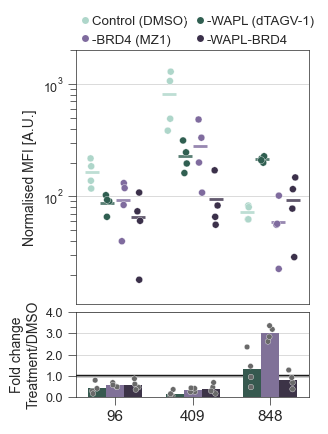

In [8]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
f, axs = plt.subplots(
    figsize=(3,4.5),
    nrows=2, 
    gridspec_kw={'height_ratios':[3,1], 'hspace':0.05}, 
    sharex=True,)

df=data_sumW

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG", "MZ1", "dTAG+MZ1"]

df=df[df["guide"].isin(order)]
df2=data_sumW_fc

g = sns.stripplot(data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette,
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5, ax=axs[0],
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette,
    hue_order=hue_order, order=order, dodge=.6, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=axs[0])

g.set(yscale="log", title="", ylim=[11, 2000])

axs[0].grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[0], markersize=6, label="Control (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[2], markersize=6, label="-BRD4 (MZ1)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[1], markersize=6, label="-WAPL (dTAGV-1)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[3], markersize=6, label="-WAPL-BRD4")
]

axs[0].legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

axs[0].tick_params(
    axis='x',          
    which='both',      
    bottom=False,      
    top=False,        
    labelbottom=False)

h = sns.barplot(data=df2, y="FC", x="guide", hue="treatment",
                  order=order, dodge=True, edgecolor="white", 
                  linewidth=0, alpha=1, ax=axs[1], width=0.7, 
                  palette=palette[1:], legend=False, errorbar=None)
sns.stripplot(data=df2, y="FC", x="guide", hue="treatment",
                  order=order, palette=["dimgrey"]*3,
                  dodge=0.25, jitter=0.1, edgecolor="white",  size=4, 
                  linewidth=0.25, alpha=1, zorder=5, ax=axs[1], legend=False)
h.set(title='', ylim=[0, 2], xlabel="")
plt.yticks([0, 1, 2, 3, 4])
axs[1].axhline(1, color="k", zorder=0, linewidth=1.75)
axs[1].grid(True, axis="y", zorder=-1, linewidth=0.5)
axs[0].set_ylabel("Normalised MFI [A.U.]", fontsize=10)
axs[1].set_ylabel("Fold change\nTreatment/DMSO", fontsize=10)
axs[0].tick_params(axis='y', labelsize=9)
axs[1].tick_params(axis='y', labelsize=9)
axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

In [9]:
df = data_sumW.sort_values("rep")
pval = pd.DataFrame()
for guide in guides:
    if guide not in ["206", "0"]:
        x = df.loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "median_minus_bg"].tolist()
        y = df.loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "median_minus_bg"].tolist()
        wc = ttest_rel(x, y, alternative="two-sided") 
        pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x), "Condition": "dTAGNIPBL-dTAGV-1"})])
        x = df.loc[(df["guide"] == guide) & (df["treatment"]=="MZ1"), "median_minus_bg"].tolist()
        wc = ttest_rel(x, y, alternative="two-sided")
        pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x), "Condition": "dTAGNIPBL-MZ1"})])
        x = df.loc[(df["guide"] == guide) & (df["treatment"]=="dTAG+MZ1"), "median_minus_bg"].tolist()
        wc = ttest_rel(x, y, alternative="two-sided")
        pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x), "Condition": "dTAGNIPBL-dTAGV-1+MZ1"})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["Condition"] = pval["Guide"] + "_" + pval["Condition"] 
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["test"] = "ttest_rel"
pval.drop(columns=["Guide"]).sort_values("pval")

,pval,N,Condition,padj,sig,log10_p,test
0,0.000035,4,848_dTAGNIPBL-dTAGV-1,0.000314,True,3.502605,ttest_rel
0,0.020359,4,96_dTAGNIPBL-dTAGV-1,0.073687,False,1.132607,ttest_rel
0,0.028900,4,96_dTAGNIPBL-MZ1,0.073687,False,1.132607,ttest_rel
0,0.032750,4,96_dTAGNIPBL-dTAGV-1+MZ1,0.073687,False,1.132607,ttest_rel
0,0.053221,4,409_dTAGNIPBL-dTAGV-1+MZ1,0.081008,False,1.091470,ttest_rel
0,0.054006,4,409_dTAGNIPBL-dTAGV-1,0.081008,False,1.091470,ttest_rel
0,0.085226,4,409_dTAGNIPBL-MZ1,0.109576,False,0.960285,ttest_rel
0,0.411402,4,848_dTAGNIPBL-MZ1,0.462827,False,0.334581,ttest_rel
0,0.484701,4,848_dTAGNIPBL-dTAGV-1+MZ1,0.484701,False,0.314526,ttest_rel


In [10]:
data_sumN["cell_line"] = "NIPBL"
data_sumW["cell_line"] = "WAPL"
data_sumB = pd.concat([data_sumN, data_sumW]).reset_index(drop=True)
data_sumB["rep"] = data_sumB["rep"].astype(str) + data_sumB["cell_line"]

In [11]:
palette=["#83aac3", "#7f6b9e"]

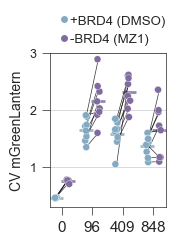

In [12]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,2), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

df = data_sumB
order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "MZ1"]

df=df[df["guide"].isin(order)]

g = sns.stripplot(data=df, y="CV", x="guide", hue="treatment", palette=palette,
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5,
                  linewidth=0.25, alpha=1, zorder=10)

sns.pointplot(
    data=df, y="CV", x="guide", hue="treatment", palette=palette,
    hue_order=hue_order, order=order, dodge=.4, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=g)

for date in df["rep"].unique():
    dfpiv = df.loc[(df["rep"]==date),["treatment", "CV","guide"]].pivot(columns="treatment", values="CV", index="guide").reset_index()
    i = 0
    for guide in order:
        if guide in dfpiv["guide"].unique():
            g.plot([i-0.2, i+0.2], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'black', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set(title="", xlabel="")

g.grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[0], markersize=6, label="+BRD4 (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[1], markersize=6, label="-BRD4 (MZ1)")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=1,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

plt.yticks([1,2,3])
plt.ylim([0.3,3])
g.set_ylabel("CV mGreenLantern", fontsize=10)
g.tick_params(axis='y', labelsize=9)

In [13]:
df = data_sumB
df["rep"] = df["rep"].astype(str)
df = df.sort_values("rep")
pval = pd.DataFrame()
for guide in guides:
    if guide not in ["206"]:
        x = df.loc[(df["guide"] == guide) & (df["treatment"]=="MZ1"), "CV"].tolist()
        y = df.loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "CV"].tolist()
        wc = ttest_rel(x, y, alternative="two-sided") 
        pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x)})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["Condition"] = pval["Guide"]
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = "+BRD4 vs -BRD4 CV"
pval["test"] = "ttest_rel"
pval.drop(columns=["Guide"]).sort_values("padj")

,pval,N,Condition,padj,sig,log10_p,test
0,0.000461,4,+BRD4 vs -BRD4 CV,0.001063,True,2.973439,ttest_rel
0,0.000532,8,+BRD4 vs -BRD4 CV,0.001063,True,2.973439,ttest_rel
0,0.001878,8,+BRD4 vs -BRD4 CV,0.002504,True,2.601434,ttest_rel
0,0.075272,8,+BRD4 vs -BRD4 CV,0.075272,False,1.123367,ttest_rel


In [14]:
palette=["#83aac3", "#3c627c", "#ea9648", "#c96d18", "#aed6ca", "#305f51"]

In [15]:
data_sumW["source"] = "file3"

df1 = pd.read_table("WAPL_data_1.txt")
df1["source"] = "file1"

df2 = pd.read_table("WAPL_data_2.txt").dropna(subset="treatment")
df2["source"] = "file2"

data_sumW2 = pd.concat([df1, df2])
data_sumW3 = pd.concat([data_sumW, data_sumW2]).reset_index(drop=True)

data_sumW3["Rep"] = pd.factorize(
    data_sumW3["source"].astype(str) + "_" + data_sumW3["rep"].astype(str)
)[0] + 1

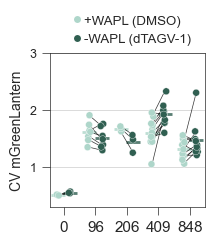

In [16]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2,2), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
df=data_sumW3

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG"]

df=df[df["guide"].isin(order)]

g = sns.stripplot(data=df, y="CV", x="guide", hue="treatment", palette=palette[4:],
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5,
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="CV", x="guide", hue="treatment", palette=palette[4:],
    hue_order=hue_order, order=order, dodge=.4, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=g)

for date in df["Rep"].unique():
    dfpiv = df.loc[(df["Rep"]==date),["treatment", "CV","guide"]].pivot(columns="treatment", values="CV", index="guide").reset_index()
    i = 0
    for guide in order:
        if guide in dfpiv["guide"].unique():
            g.plot([i-0.2, i+0.2], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'black', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set(title="", xlabel="")

g.grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[4], markersize=6, label="+WAPL (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[5], markersize=6, label="-WAPL (dTAGV-1)")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=1,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

plt.yticks([1,2,3])
plt.ylim([0.3,3])
g.set_ylabel("CV mGreenLantern", fontsize=10)
g.tick_params(axis='y', labelsize=9)

In [17]:
df = data_sumW3
df["Rep"] = df["Rep"].astype(str)
df = df.sort_values("Rep")
pval = pd.DataFrame()
for guide in guides:
    x = df.loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "CV"].tolist()
    y = df.loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "CV"].tolist()
    wc = ttest_rel(x, y, alternative="two-sided") 
    pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x)})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["Condition"] = pval["Guide"]
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = "+WAPL vs -WAPL CV"
pval["test"] = "ttest_rel"
pval.drop(columns=["Guide"]).sort_values("padj")

,pval,N,Condition,padj,sig,log10_p,test
0,0.001297,11,+WAPL vs -WAPL CV,0.006487,True,2.187987,ttest_rel
0,0.055978,3,+WAPL vs -WAPL CV,0.089257,False,1.049359,ttest_rel
0,0.064506,7,+WAPL vs -WAPL CV,0.089257,False,1.049359,ttest_rel
0,0.071405,3,+WAPL vs -WAPL CV,0.089257,False,1.049359,ttest_rel
0,0.097068,11,+WAPL vs -WAPL CV,0.097068,False,1.012922,ttest_rel


In [18]:
data_sumN["source"] = "file3"

df1 = pd.read_table("NIPBL_data_1.txt")
df1["source"] = "file1"

df2 = pd.read_table("NIPBL_data_2.txt").dropna(subset="treatment")
df2["source"] = "file2"

data_sumN2 = pd.concat([df1, df2])
data_sumN3 = pd.concat([data_sumN, data_sumN2]).reset_index(drop=True)

data_sumN3["Rep"] = pd.factorize(
    data_sumN3["source"].astype(str) + "_" + data_sumN3["rep"].astype(str)
)[0] + 1

/local/55263823.1.igmm_long/ipykernel_1278144/3631935244.py:11: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  g = sns.stripplot(data=df, y="CV", x="guide", hue="treatment", palette=palette,
/local/55263823.1.igmm_long/ipykernel_1278144/3631935244.py:14: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.pointplot(


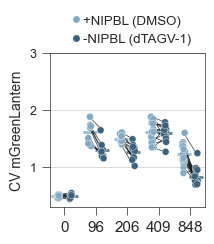

In [19]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2,2), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
df=data_sumN3

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG"]

df=df[df["guide"].isin(order)]

g = sns.stripplot(data=df, y="CV", x="guide", hue="treatment", palette=palette,
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5,
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="CV", x="guide", hue="treatment", palette=palette,
    hue_order=hue_order, order=order, dodge=.4, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=g)

for date in df["Rep"].unique():
    dfpiv = df.loc[(df["Rep"]==date),["treatment", "CV","guide"]].pivot(columns="treatment", values="CV", index="guide").reset_index()
    i = 0
    for guide in order:
        if guide in dfpiv["guide"].unique():
            g.plot([i-0.2, i+0.2], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'black', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set(title="", xlabel="")

g.grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[0], markersize=6, label="+NIPBL (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[1], markersize=6, label="-NIPBL (dTAGV-1)")
]

g.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=1,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

plt.yticks([1,2,3])
plt.ylim([0.3,3])
g.set_ylabel("CV mGreenLantern", fontsize=10)
g.tick_params(axis='y', labelsize=9)

In [20]:
df = data_sumN3
df["Rep"] = df["Rep"].astype(str)
df = df.sort_values("Rep")
pval = pd.DataFrame()
for guide in guides:
    x = df.loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "CV"].tolist()
    y = df.loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "CV"].tolist()
    wc = ttest_rel(x, y, alternative="two-sided") 
    pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x)})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["Condition"] = pval["Guide"]
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = "+NIPBL vs -NIPBL CV"
pval["test"] = "ttest_rel"
pval.drop(columns=["Guide"]).sort_values("padj")

,pval,N,Condition,padj,sig,log10_p,test
0,0.000007,15,+NIPBL vs -NIPBL CV,0.000034,True,4.470777,ttest_rel
0,0.000139,9,+NIPBL vs -NIPBL CV,0.000238,True,3.622531,ttest_rel
0,0.000143,10,+NIPBL vs -NIPBL CV,0.000238,True,3.622531,ttest_rel
0,0.080611,8,+NIPBL vs -NIPBL CV,0.100763,False,0.996698,ttest_rel
0,0.471190,16,+NIPBL vs -NIPBL CV,0.471190,False,0.326804,ttest_rel
